# Employee Attrition Prediction

Employee turnover is a major challenge for organizations, as losing employees can increase recruitment costs and affect overall productivity. Understanding the factors associated with employee attrition can help organizations identify potential risks and make better retention decisions.

In this project, exploratory data analysis was performed to identify patterns and factors related to employee attrition. A Logistic Regression model was developed to predict whether an employee is likely to leave the company based on different personal, job-related, and satisfaction features.

Logistic Regression was selected as the main model due to its interpretability, allowing better understanding of how different factors influence the likelihood of employee attrition.

## Project Objective

The main objective is to analyze employee characteristics and build a classification model that predicts employee attrition while identifying the key factors associated with turnover.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition 3.csv")

# 1) Data Understanding


In [2]:
df.shape

(1470, 35)

In [3]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [5]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# 2) Data Cleaning


In [6]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["Attrition"]=df["Attrition"].map({"No": 0,"Yes": 1})

# Exploratory Data Analysis (EDA)


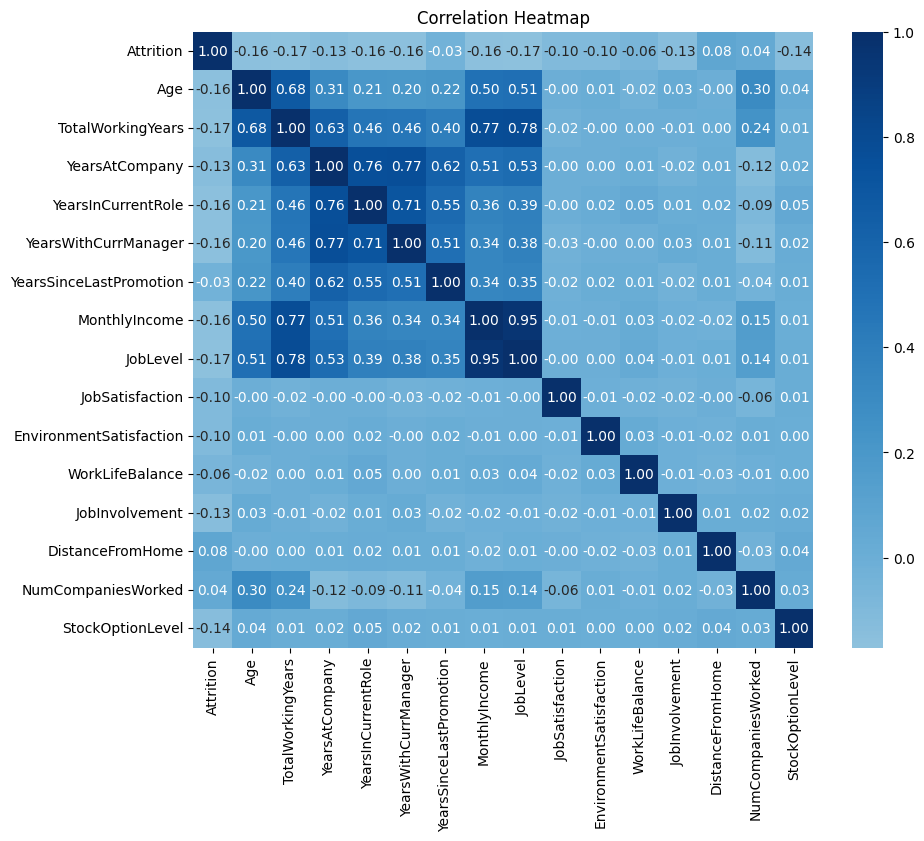

In [9]:
cols=[
    "Attrition",
    "Age",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager",
    "YearsSinceLastPromotion",
    "MonthlyIncome",
    "JobLevel",
    "JobSatisfaction",
    "EnvironmentSatisfaction",
    "WorkLifeBalance",
    "JobInvolvement",
    "DistanceFromHome",
    "NumCompaniesWorked",
    "StockOptionLevel"]

plt.figure(figsize=(10, 8))
sns.heatmap(
    df[cols].corr(),
    annot=True,
    cmap="Blues",
    center=0,
    fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

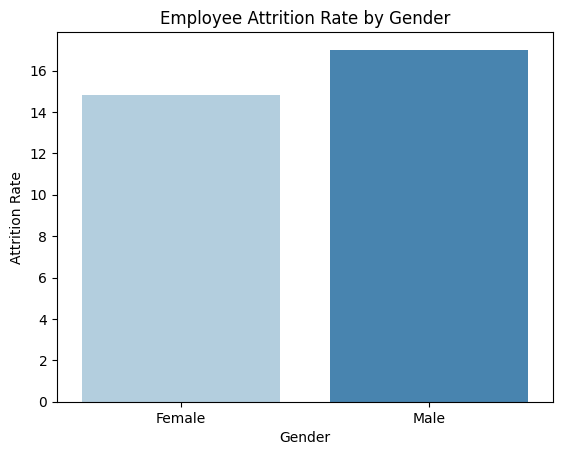

In [10]:
rate=(
    df.groupby("Gender")["Attrition"]
    .mean()
    .reset_index())
rate["AttritionRate"]=rate["Attrition"] * 100
sns.barplot(
    data=rate,
    x="Gender",
    y="AttritionRate",
    hue="Gender",
    palette="Blues",
    legend=False)

plt.ylabel("Attrition Rate")
plt.title("Employee Attrition Rate by Gender")
plt.show()

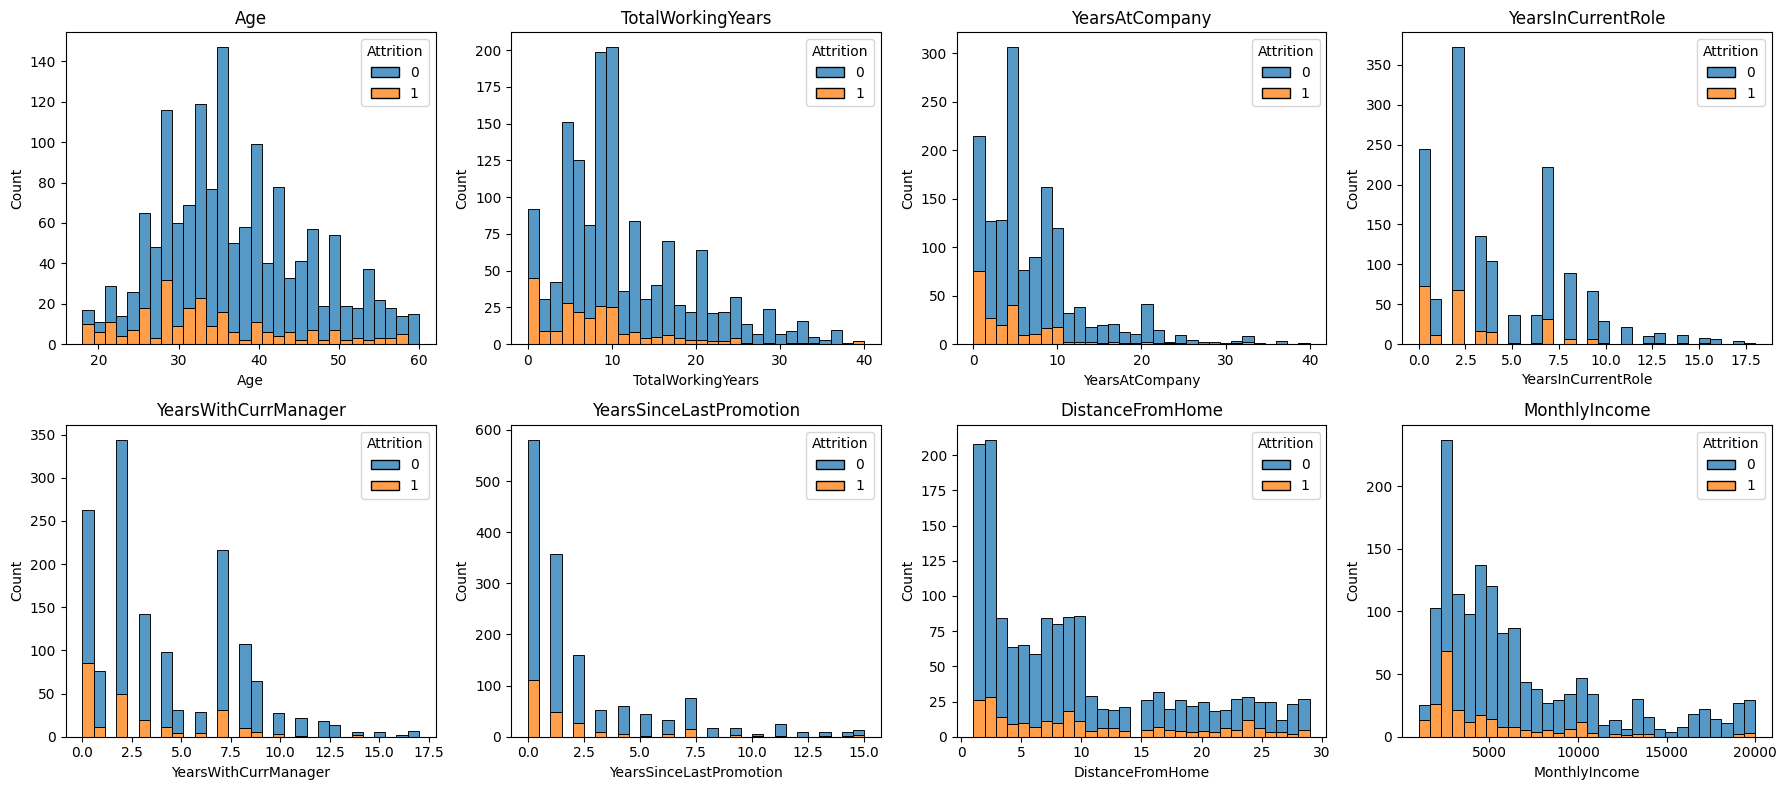

In [11]:
cols=[
    "Age",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager",
    "YearsSinceLastPromotion", 
    "DistanceFromHome",
    "MonthlyIncome",]
fig,axes=plt.subplots(2,4,figsize=(18, 8))

for ax, col in zip(axes.flat, cols):
    sns.histplot(
        data=df,
        x=col,
        hue="Attrition",
        bins=30,
        multiple="stack",
        ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Observations

* Employees who left the company are more concentrated in the **lowest tenure values** across most experience-related features, although departures still occur at higher tenure levels.
* A noticeable peak is also observed around a **monthly income of approximately 2,500**, which may indicate a pattern worth further investigation.
* **DistanceFromHome** does not show a clear pattern that distinguishes employees who left from those who stayed.


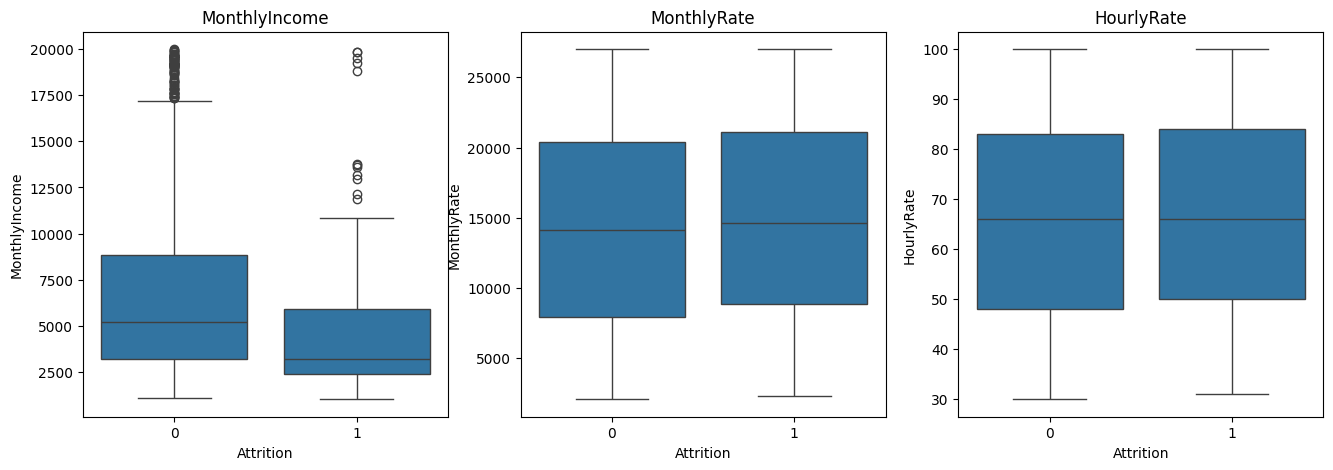

In [12]:
cols = ["MonthlyIncome", "MonthlyRate", "HourlyRate"]
fig,axes=plt.subplots(1,3,figsize=(16,5))

for ax, col in zip(axes, cols):
    sns.boxplot(
        data=df,
        x="Attrition",
        y=col,
        ax=ax)
    ax.set_title(col)
plt.show()

### Salary Analysis

Monthly Income showed a clearer difference between employees who left and stayed compared to Monthly Rate and Hourly Rate, indicating that income level may have a stronger association with employee attrition.

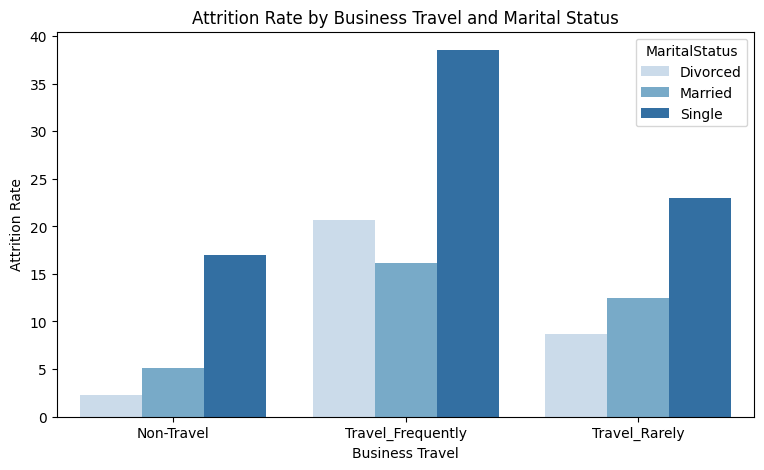

In [13]:
travel_marital_attrition=(
    df.groupby(["BusinessTravel", "MaritalStatus"])["Attrition"]
    .mean()
    .mul(100)
    .reset_index())

plt.figure(figsize=(9,5))

sns.barplot(
    data=travel_marital_attrition,
    x="BusinessTravel",
    y="Attrition",
    hue="MaritalStatus",
    palette="Blues")

plt.title("Attrition Rate by Business Travel and Marital Status")
plt.xlabel("Business Travel")
plt.ylabel("Attrition Rate")

plt.show()

### Additional Attrition Factors

Single employees had the highest attrition rate despite not being the largest group. In addition, frequent business travelers showed higher attrition rates, suggesting a possible relationship between these factors and employee turnover.

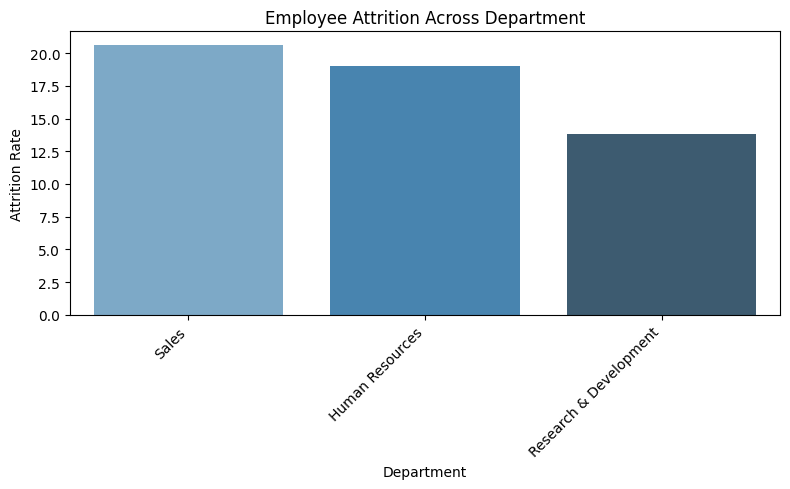

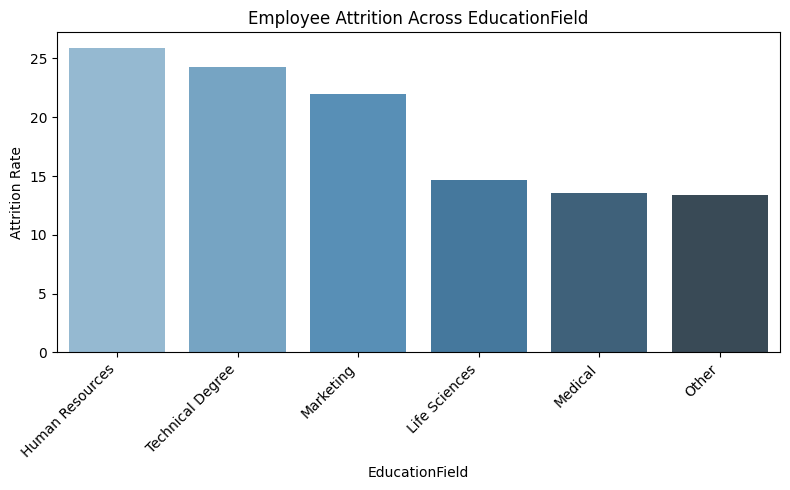

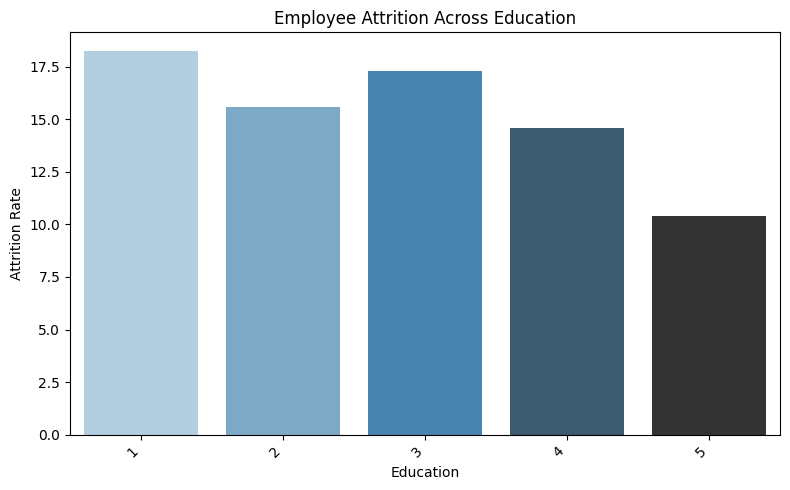

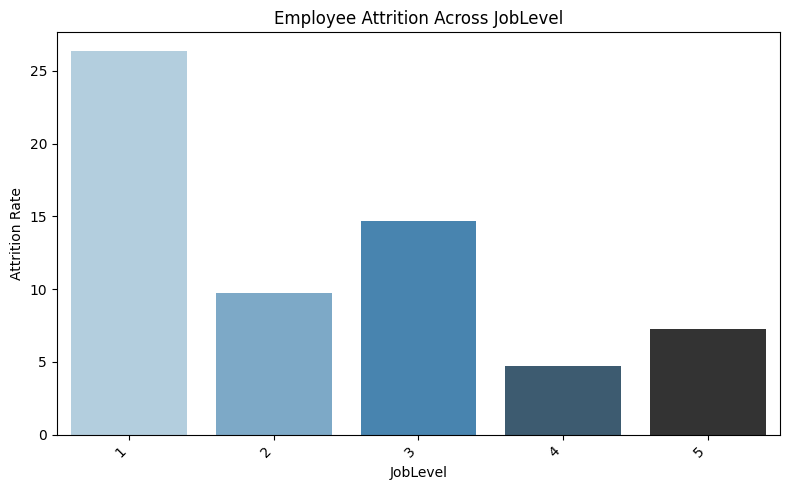

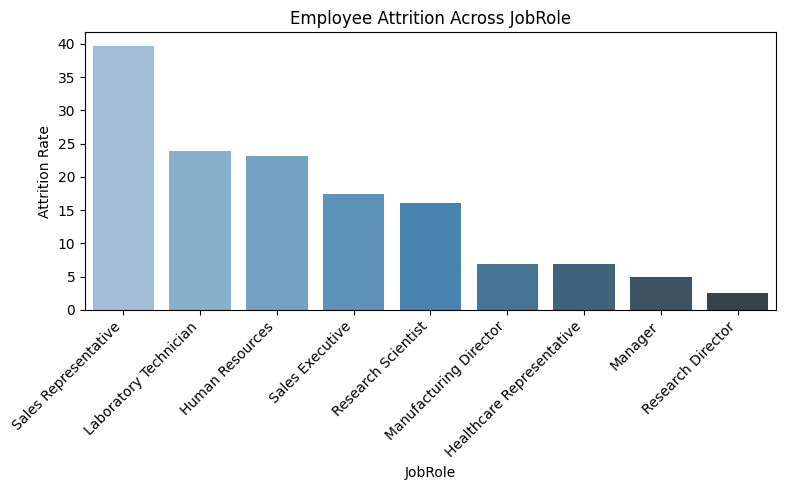

In [14]:
cat_cols=["Department","EducationField","Education","JobLevel","JobRole"]
for col in cat_cols:
    rate=(
        df.groupby(col)["Attrition"]
        .mean()
        .sort_values(ascending=False)
        * 100)

    plt.figure(figsize=(8,5))
    sns.barplot(
        x=rate.index,
        y=rate.values,
        hue=rate.index,
        palette="Blues_d",
        legend=False)

    plt.title(f"Employee Attrition Across {col}")
    plt.ylabel("Attrition Rate")
    plt.xlabel(col)
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

In [15]:
pd.crosstab(df["Department"],df["JobRole"])

JobRole,Healthcare Representative,Human Resources,Laboratory Technician,Manager,Manufacturing Director,Research Director,Research Scientist,Sales Executive,Sales Representative
Department,,,,,,,,,
Human Resources,0,52,0,11,0,0,0,0,0
Research & Development,131,0,259,54,145,80,292,0,0
Sales,0,0,0,37,0,0,0,326,83


### Department Composition

The **Research & Development** department has a more diverse mix of job roles, including roles with relatively lower attrition rates. Additionally, employees in higher job levels, such as managers and directors, generally showed lower attrition, which may influence the overall attrition pattern across departments. Other departments are more concentrated in fewer job roles, some of which show higher attrition rates. For **Human Resources**, the noticeable income gap between employees who stayed and those who left may also be worth further investigation.

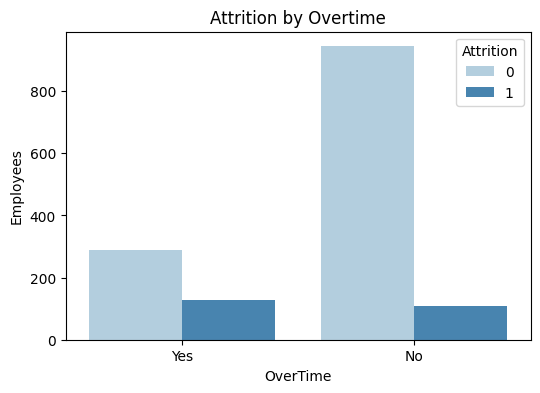

In [16]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="OverTime",
    hue="Attrition",
    palette="Blues")

plt.title("Attrition by Overtime")
plt.xlabel("OverTime")
plt.ylabel("Employees")
plt.show()

### Key Findings

Job Satisfaction and Environment Satisfaction had the largest gap between stayed and left employees, suggesting a stronger association with attrition. Overtime also showed a clear relationship with employee turnover, with higher attrition among employees working overtime.

# 3) Baseline Model

In [17]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

categorical_cols = df.select_dtypes(include=["object","category"]).columns
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

In [18]:
x=df.drop(columns="Attrition")
y=df["Attrition"]
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.7,random_state=42,stratify=y)

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

baseline_model = LogisticRegression(
    solver="newton-cholesky",   
      random_state=42)

baseline_model.fit(x_train, y_train)

baseline_pred = baseline_model.predict(x_test)

baseline_acc = round(baseline_model.score(x_test, y_test) * 100, 2)

print(classification_report(y_test, baseline_pred))

print("Accuracy:", baseline_acc)

              precision    recall  f1-score   support

           0       0.88      0.97      0.92       370
           1       0.66      0.30      0.41        71

    accuracy                           0.86       441
   macro avg       0.77      0.63      0.66       441
weighted avg       0.84      0.86      0.84       441

Accuracy: 86.17


# 4) Feature Engineering

Based on the EDA findings, new features were created to capture patterns related to career stage and income level.
- **FirstYear:** Captures employees in their first or second year at the company, as early-tenure employees showed noticeable attrition patterns.
- **AgeGroup:** Groups employees into different career stages to better represent the relationship between age and attrition.
- **FirstCareerYear:** Identifies employees at the beginning of their careers, as early-career employees showed higher attrition patterns.

In [20]:
df["AgeGroup"] = pd.cut( df["Age"], 
bins=[17, 25, 35, 45, 60], labels=["Young","Early Career","Mid Career","Senior"]) 
df["AgeGroup"] = le.fit_transform(df["AgeGroup"])

In [21]:
df["FirstYear"]=np.where(df["YearsAtCompany"]<=1, 1, 0)

In [22]:
df["FirstCareerYear"]=np.where(df["TotalWorkingYears"]<=1, 1, 0)

In [23]:
df = df.drop(columns=["EmployeeCount","StandardHours","EmployeeNumber","Over18"])

# 6) Modeling

In [24]:
x=df.drop(columns="Attrition")
y=df["Attrition"]
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.7,random_state=42,stratify=y)

In [25]:
logreg=LogisticRegression(solver="newton-cholesky",random_state=42)

model=logreg.fit(x_train,y_train)
y_pred=logreg.predict(x_test)
acc_log=round(logreg.score(x_test, y_test) * 100, 2)

print("CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))
print("accuracy :",round(model.score(x_test, y_test) * 100, 2))

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.88      0.98      0.93       370
           1       0.73      0.34      0.46        71

    accuracy                           0.87       441
   macro avg       0.81      0.66      0.69       441
weighted avg       0.86      0.87      0.85       441

accuracy : 87.3


## Conclusion

This analysis highlighted several factors associated with employee attrition. Employees with lower satisfaction levels, overtime requirements, and early career stages showed higher attrition patterns. Monthly Income also showed a clearer difference between employees who left and those who stayed compared to other salary-related features.

Additionally, frequent business travel and marital status showed noticeable differences in attrition rates. These findings suggest that employee experience, workload, and career progression factors may play an important role in retention.

A Logistic Regression model was developed to predict employee attrition, providing an interpretable approach to understand the factors associated with employees leaving the company.